In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt

In [19]:
from Scratch import ScratchLinearRegression

In [20]:
df = pd.read_csv('my_house_data.csv')


In [21]:
X = df.drop('Price', axis=1)
y = df['Price']

In [22]:
X_train, X_test, y_train , y_test = train_test_split(X, y, test_size=0.3,random_state=42)

In [23]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train) 
X_test = scaler.transform(X_test)

In [24]:
# --- 1. NORMAL LINEAR REGRESSION ---
model_normal = ScratchLinearRegression(learning_rate=0.01, iterations=2000, penalty = None)
model_normal.fit(X_train, y_train)
score_normal = r2_score(y_test, model_normal.predict(X_test))

In [25]:
# --- 2. RIDGE REGRESSION (L2) ---
# We turn on the penalty and set alpha (punishment strength) to 10.0
model_ridge = ScratchLinearRegression(learning_rate=0.01, iterations=2000, penalty = 'ridge' , alpha = 0.1)
model_ridge.fit(X_train, y_train)
score_ridge = r2_score(y_test, model_ridge.predict(X_test))

In [26]:
# --- 3. LASSO REGRESSION (L1) ---
model_lasso = ScratchLinearRegression(learning_rate=0.01, iterations=2000, penalty='lasso', alpha=1.0)
model_lasso.fit(X_train, y_train)
score_lasso = r2_score(y_test, model_lasso.predict(X_test))

In [28]:
# --- THE GRAND REVEAL: COMPARING THE WEIGHTS ---
# This is where you see the magic of the math we just wrote!
print("=== MODEL ACCURACY SCORES ===")
print(f"Normal Score: {score_normal:.4f}")
print(f"Ridge Score:  {score_ridge:.4f}")
print(f"Lasso Score:  {score_lasso:.4f}")
print("\n=== THE WEIGHTS (Notice how Ridge/Lasso shrink them!) ===")
print("Normal Weights:", np.round(model_normal.weights, 2))
print("Ridge Weights: ", np.round(model_ridge.weights, 2))
print("Lasso Weights: ", np.round(model_lasso.weights, 2))

=== MODEL ACCURACY SCORES ===
Normal Score: 0.9927
Ridge Score:  0.9863
Lasso Score:  0.9927

=== THE WEIGHTS (Notice how Ridge/Lasso shrink them!) ===
Normal Weights: [ 6.139749e+04  1.505560e+03 -7.694870e+03  4.781000e+01 -1.284120e+03
  6.136868e+04]
Ridge Weights:  [ 44079.21  20282.14 -20724.46   1730.85   -613.9   44069.44]
Lasso Weights:  [ 6.139758e+04  1.505190e+03 -7.694500e+03  4.733000e+01 -1.283660e+03
  6.136877e+04]


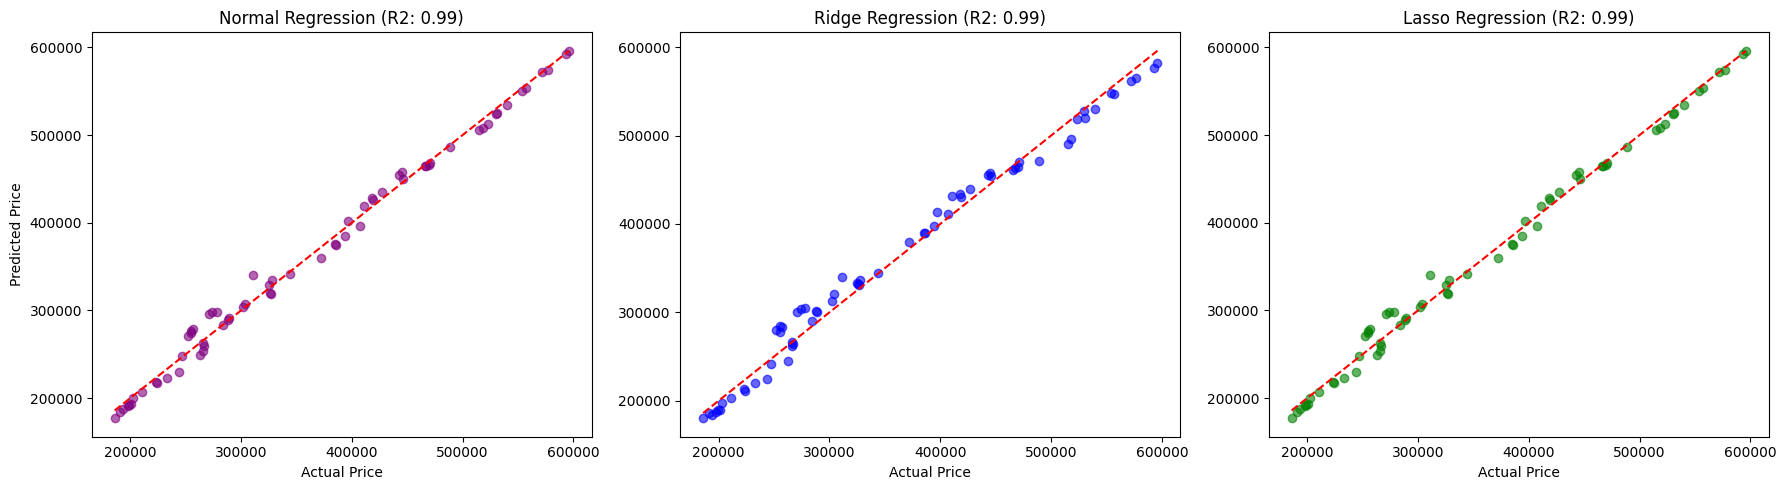

In [29]:
# Create a wide canvas with 3 graphs side-by-side (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- GRAPH 1: Normal Regression ---
axes[0].scatter(y_test, model_normal.predict(X_test), color='purple', alpha=0.6)
axes[0].plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
axes[0].set_title(f"Normal Regression (R2: {score_normal:.2f})")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")

# --- GRAPH 2: Ridge Regression ---
axes[1].scatter(y_test, model_ridge.predict(X_test), color='blue', alpha=0.6)
axes[1].plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
axes[1].set_title(f"Ridge Regression (R2: {score_ridge:.2f})")
axes[1].set_xlabel("Actual Price")

# --- GRAPH 3: Lasso Regression ---
axes[2].scatter(y_test, model_lasso.predict(X_test), color='green', alpha=0.6)
axes[2].plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linestyle='--')
axes[2].set_title(f"Lasso Regression (R2: {score_lasso:.2f})")
axes[2].set_xlabel("Actual Price")

# Show the final masterpiece
plt.tight_layout() # Keeps the graphs from squishing together
plt.show()